# 04 · Which risk model can the endowment rely on? Out-of-sample backtesting

**Owner:** team lead · **Reviewed by:** _[name]_ · **Covers:** brief Layer 5 (Kupiec, Christoffersen, Basel traffic light), Layer 4 "how different modelling approaches perform under stressed market conditions", gaps G9, G20, G28, hypotheses H3–H4
**Status:** analysis drafted with AI assistance; the owner re-runs it, checks every finding and rewrites it before sign-off (gap G12).

**The business question.** A risk number is only useful if it is right about as often as it claims. A 99% VaR should be exceeded on about 1 day in 100, and the exceedances should not bunch together. We test six models on the portfolio we are likely to recommend, choose the one the committee will rely on **using 2019–2022 only** (the validation period), and keep 2023–2026 sealed for the one-shot final test after the freeze (30 October 2026).

**What is tested.** The 35%-equity point of the minimum-variance frontier (notebook 02), rebuilt every quarter from the previous three years only. Each day's VaR uses only data up to the day before: the model sees the last 500 days of the portfolio it holds **today** (pro-forma history), is refitted every 5 days or when the weights change, and rolls its volatility filter forward one day at a time in between.

| Model | Idea |
|---|---|
| Historical | the last 500 days, no distribution assumed |
| Normal | mean and standard deviation of the last 500 days |
| GARCH-FHS | GARCH(1,1) volatility forecast × the empirical quantiles of past standardised residuals |
| **GJR-FHS** | the same with GJR-GARCH (losses raise volatility more than gains), notebook 03 §5 |
| Conditional EVT | GARCH(1,1) + a Generalised Pareto tail on the standardised residuals (the pipeline's current champion) |
| **GJR conditional EVT** | the same with GJR-GARCH |

**Locked champion rule (inputs_lock):** among models that pass Kupiec, Christoffersen and the Basel traffic light on validation, the one with the lowest 99% pinball loss.

In [1]:
from pathlib import Path
import hashlib, json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, kpss
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=InterpolationWarning)

ROOT = Path.cwd().parent if (Path.cwd().parent / "data" / "raw").exists() else Path.cwd()
RAW, ART = ROOT / "data" / "raw", ROOT / "data" / "artifacts"
END = "2022-12-31"                      # test lock: nothing after this date
TICKERS = ["SPY", "EFA", "EEM", "AGG", "GLD", "XLE", "XLK"]
pd.set_option("display.width", 160, "display.precision", 4)

# chart style: validated reference palette, thin marks, recessive grid, text in ink colours
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8c8b86"
INK, INK2, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": "#e8e7e3", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "legend.frameon": False,
    "figure.figsize": (9, 4), "figure.dpi": 110,
})

In [2]:
import time
from scipy import optimize
from scipy import stats as st
from sklearn.covariance import LedoitWolf
from arch import arch_model
import statsmodels.api as sm

raw = pd.read_parquet(RAW / "prices.parquet")
raw["date"] = pd.to_datetime(raw["date"])
raw = raw[raw["date"] <= END]
adj = raw.pivot(index="date", columns="ticker", values="adj_close").sort_index()[TICKERS]
R = adj.pct_change(fill_method=None).iloc[1:]
EQUITY = ["SPY", "EFA", "EEM", "XLE", "XLK"]
EQ = np.array([t in EQUITY for t in TICKERS], float)
CAPS = {"SPY": .40, "EFA": .40, "EEM": .10, "XLE": .10, "XLK": .10, "GLD": .15, "AGG": .65}   # D3 (agreed)
X_EQ, W_OPT, W_RISK, REFIT = 0.35, 756, 500, 5
SCALE = 1000            # GARCH is fitted on per-mille returns: a conservative portfolio's daily % variance (~0.08) is too small for the optimiser
ALPHAS = (0.95, 0.975, 0.99)
VAL = ("2019-01-01", END)

def min_var_at(x, S):
    res = optimize.minimize(lambda w: w @ S @ w, np.full(7, 1 / 7), method="SLSQP",
                            bounds=[(0.0, CAPS[t]) for t in TICKERS],
                            constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1},
                                         {"type": "eq", "fun": lambda w: EQ @ w - x}], options={"ftol": 1e-12})
    assert res.success, res.message
    return np.clip(res.x, 0, None) / np.clip(res.x, 0, None).sum()

qe = R.index.to_series().groupby(R.index.to_period("Q")).max()
TAUS = [d for d in qe if pd.Timestamp("2007-12-31") <= d < R.index[-1]]
WPATH = {tau: min_var_at(X_EQ, LedoitWolf().fit(R.loc[:tau].iloc[-W_OPT:].to_numpy()).covariance_ * 252) for tau in TAUS}
DAYS = R.index[R.index > TAUS[0]]
held = pd.DataFrame(WPATH).T.reindex(R.index, method="ffill").shift(1).loc[DAYS]   # weights held during each day
print(f"{len(TAUS)} quarterly rebalances; {len(DAYS)} forecast days {DAYS[0].date()} to {DAYS[-1].date()}")

60 quarterly rebalances; 3777 forecast days 2008-01-02 to 2022-12-30


## 1 · Forecasting every day without looking ahead

The forecast for day t is built from returns dated t−500 … t−1 valued at the weights held on day t. An assertion checks on every day that the window ends before t.

In [3]:
def at_es(x, a):
    x = np.sort(np.asarray(x))[::-1]; m = (1 - a) * len(x); k = int(np.floor(m + 1e-12))
    return float((x[:k].sum() + ((m - k) * x[k] if m - k > 1e-12 else 0.0)) / m)

def gpd_tail(zl, a, k_frac=0.10):
    # VaR and ES of standardised losses zl from a GPD fitted above the (1 - k_frac) quantile
    u = np.quantile(zl, 1 - k_frac); y = zl[zl > u] - u
    xi, _, beta = st.genpareto.fit(y, floc=0)
    n, k = len(zl), len(y)
    q = u + beta / xi * ((n / k * (1 - a)) ** (-xi) - 1) if abs(xi) > 1e-6 else u - beta * np.log(n / k * (1 - a))
    es = q / (1 - xi) + (beta - xi * u) / (1 - xi) if xi < 1 else np.inf
    return q, es

def run_model(kind):
    Rv, Wv, idx = R.to_numpy(), held.to_numpy(), R.index
    rows, state, last_w, last_fit = [], None, None, -10**9
    for d in DAYS:
        i = idx.get_loc(d); w = Wv[DAYS.get_loc(d)]
        hist = Rv[i - W_RISK:i] @ w
        assert idx[i - 1] < d, "look-ahead"
        loss = float(-(Rv[i] @ w))
        row = {"date": d, "loss": loss}
        if kind == "Historical":
            l = -hist
            for a in ALPHAS:
                row[f"var_{a}"] = float(np.quantile(l, a, method="higher")); row[f"es_{a}"] = at_es(l, a)
        elif kind == "Normal":
            m, s = -hist.mean(), hist.std(ddof=1)
            for a in ALPHAS:
                z = st.norm.ppf(a); row[f"var_{a}"] = m + z * s; row[f"es_{a}"] = m + s * st.norm.pdf(z) / (1 - a)
        else:
            gjr = kind.startswith("GJR")
            changed = last_w is None or not np.allclose(w, last_w)
            if state is None or changed or (i - last_fit) >= REFIT:
                res = arch_model(SCALE * hist, mean="Constant", vol="GARCH", p=1, o=1 if gjr else 0, q=1, dist="t").fit(disp="off")
                p = res.params
                eps_last = SCALE * hist[-1] - p["mu"]; var_last = res.conditional_volatility[-1] ** 2
                z = np.asarray(res.std_resid); zl = -z[np.isfinite(z)]
                tail = {a: (gpd_tail(zl, a) if "EVT" in kind else (float(np.quantile(zl, a, method="higher")), at_es(zl, a)))
                        for a in ALPHAS}                               # tail of the standardised losses, fixed until the next refit
                state = {"p": p, "tail": tail, "eps": eps_last, "var": var_last}
                last_fit, last_w = i, w
            else:                                                      # roll the filter forward one day, fixed parameters
                eps = SCALE * (Rv[i - 1] @ w) - state["p"]["mu"]
                state["var"] = (state["p"]["omega"] + (state["p"]["alpha[1]"] + state["p"].get("gamma[1]", 0.0) * (state["eps"] < 0))
                                * state["eps"] ** 2 + state["p"]["beta[1]"] * state["var"])
                state["eps"] = eps
            p = state["p"]
            g = p.get("gamma[1]", 0.0)
            sig2 = p["omega"] + (p["alpha[1]"] + g * (state["eps"] < 0)) * state["eps"] ** 2 + p["beta[1]"] * state["var"]
            sig, mu = np.sqrt(sig2) / SCALE, p["mu"] / SCALE
            for a in ALPHAS:
                q, es = state["tail"][a]
                row[f"var_{a}"] = -mu + sig * q; row[f"es_{a}"] = -mu + sig * es
        rows.append(row)
    out = pd.DataFrame(rows).set_index("date")
    for a in ALPHAS:
        out[f"hit_{a}"] = (out["loss"] > out[f"var_{a}"]).astype(int)
    return out

MODELS = ["Historical", "Normal", "GARCH-FHS", "GJR-FHS", "Conditional EVT", "GJR conditional EVT"]
fc, t0 = {}, time.time()
for m in MODELS:
    fc[m] = run_model(m)
print(f"forecasts built in {time.time() - t0:.0f} s")

forecasts built in 53 s


## 2 · Coverage, independence and the traffic light on validation (2019–2022)

- **Kupiec** (H0: the exception rate equals 1%) and **Christoffersen** (H0: an exception today does not make one tomorrow more likely).
- **Basel traffic light.** The canonical zones (green 0–4, yellow 5–9, red 10+ exceptions) are defined for 99% VaR over **250** days, so we apply them to every rolling 250-day window. For the whole 4-year period we compute **adapted** zones from the binomial distribution with the same probabilities (95% and 99.99%) and label them as adapted.
- **Pinball loss** (lower is better) scores how good the 99% quantile is, not just the count; **FZ0** scores VaR and ES jointly.

In [4]:
def kupiec(h, p=0.01):
    T, x = len(h), int(h.sum()); ph = x / T
    ll = lambda q: (T - x) * np.log(1 - q) + (x * np.log(q) if x else 0.0)
    lr = -2 * (ll(p) - (ll(ph) if 0 < x < T else 0.0))
    return x, T * p, float(st.chi2.sf(max(lr, 0), 1))

def christoffersen(h):
    a0, a1 = h[:-1], h[1:]
    n00, n01 = ((a0 == 0) & (a1 == 0)).sum(), ((a0 == 0) & (a1 == 1)).sum()
    n10, n11 = ((a0 == 1) & (a1 == 0)).sum(), ((a0 == 1) & (a1 == 1)).sum()
    if n10 + n11 == 0:
        return np.nan
    p01, p11, pp = n01 / (n00 + n01), n11 / (n10 + n11), (n01 + n11) / (len(h) - 1)
    ll = lambda k, q: k * np.log(q) if k else 0.0
    lr = -2 * (ll(n00 + n10, 1 - pp) + ll(n01 + n11, pp) - ll(n00, 1 - p01) - ll(n01, p01) - ll(n10, 1 - p11) - ll(n11, p11))
    return float(st.chi2.sf(max(lr, 0), 1))

def basel_zone(x, T, p=0.01):
    cdf = st.binom.cdf(np.arange(T + 1), T, p)
    green_max = int(np.where(cdf < 0.95)[0].max()); red_min = int(np.where(cdf >= 0.9999)[0].min())
    return "green" if x <= green_max else ("red" if x >= red_min else "yellow"), green_max, red_min

def pinball(df, a=0.99):
    u = df["loss"] - df[f"var_{a}"]
    return float(np.mean(np.where(u > 0, a * u, (a - 1) * u)))

def fz0_series(df, a=0.99):
    y, v, e, p = -df["loss"], -df[f"var_{a}"], -df[f"es_{a}"], 1 - a     # return-space quantile and ES (negative)
    return -(1 / (p * e)) * (y <= v) * (v - y) + v / e + np.log(-e) - 1

assert basel_zone(4, 250)[1:] == (4, 10)                                  # reproduces the canonical Basel table
rows = []
for m in MODELS:
    d = fc[m].loc[VAL[0]:VAL[1]]
    h = d["hit_0.99"].to_numpy()
    x, ex, kp = kupiec(h)
    ip = christoffersen(h)
    zone, gmax, rmin = basel_zone(x, len(h))
    roll = pd.Series(h, index=d.index).rolling(250).sum().dropna()
    red_share = float((roll >= 10).mean())
    passes = kp >= 0.05 and (np.isnan(ip) or ip >= 0.05) and zone != "red" and red_share == 0
    rows.append({"model": m, "days": len(h), "exceptions": x, "expected": ex, "Kupiec p": kp, "Christoffersen p": ip,
                 f"adapted zone (green ≤ {gmax}, red ≥ {rmin})": zone, "rolling 250-day windows in red": red_share,
                 "pinball (×10⁴)": pinball(d) * 1e4, "FZ0": float(fz0_series(d).mean()), "passes": passes})
val = pd.DataFrame(rows).set_index("model")
val.style.format({"expected": "{:.1f}", "Kupiec p": "{:.3f}", "Christoffersen p": "{:.3f}", "rolling 250-day windows in red": "{:.0%}",
                  "pinball (×10⁴)": "{:.3f}", "FZ0": "{:.3f}"}, na_rep="n/a")

,days,exceptions,expected,Kupiec p,Christoffersen p,"adapted zone (green ≤ 15, red ≥ 24)",rolling 250-day windows in red,pinball (×10⁴),FZ0,passes
model,,,,,,,,,,
Historical,1008,13,10.1,0.376,0.009,green,0%,3.556,-3.016,False
Normal,1008,25,10.1,0.000,0.002,red,40%,3.252,-2.348,False
GARCH-FHS,1008,12,10.1,0.555,0.591,green,0%,2.132,-3.957,True
GJR-FHS,1008,13,10.1,0.376,0.560,green,0%,2.020,-4.012,True
Conditional EVT,1008,14,10.1,0.241,0.530,green,0%,2.040,-4.002,True
GJR conditional EVT,1008,14,10.1,0.241,0.530,green,0%,1.995,-4.026,True


**Finding:** on the portfolio we are likely to recommend, the **four volatility-adjusted models pass every test** on 2019–2022: 12–14 exceptions against 10.1 expected (Kupiec p = 0.24–0.56), no clustering (Christoffersen p = 0.53–0.59), green in the adapted traffic light, and no 250-day window in red. Historical simulation has about the right **count** (13) but its exceptions **bunch together** (Christoffersen p = 0.009), which is the failure that matters in a crisis. The normal model fails everything (25 exceptions; 40% of 250-day windows red).
**Decision:** only volatility-adjusted models are eligible, as notebook 03 predicted.

## 3 · Applying the locked champion rule, and is the difference real?

The rule picks the lowest pinball loss among passing models. Because the best few models often differ by noise, we also test each challenger against the current champion (plain conditional EVT) with a **Diebold-Mariano** test on the daily pinball losses (Newey-West errors; Holm correction across the challengers).

In [5]:
def daily_pinball(df, a=0.99):
    u = df["loss"] - df[f"var_{a}"]; return np.where(u > 0, a * u, (a - 1) * u)

base = "Conditional EVT"
dv = {m: daily_pinball(fc[m].loc[VAL[0]:VAL[1]]) for m in MODELS}
rows = []
for m in MODELS:
    if m == base:
        continue
    dlt = dv[m] - dv[base]
    r = sm.OLS(dlt, np.ones(len(dlt))).fit(cov_type="HAC", cov_kwds={"maxlags": 10})
    rows.append({"challenger": m, "mean pinball difference (×10⁶)": r.params[0] * 1e6, "DM t": r.tvalues[0], "p": r.pvalues[0]})
dm = pd.DataFrame(rows).set_index("challenger").sort_values("p")
k = len(dm); dm["Holm p"] = np.minimum(1, np.maximum.accumulate(dm["p"].to_numpy() * (k - np.arange(k))))
passing = val[val["passes"]]
champion = passing["pinball (×10⁴)"].idxmin() if len(passing) else None
print(f"models passing every test on validation: {list(passing.index)}")
print(f"champion by the locked rule: {champion}")
dm.round(4)

models passing every test on validation: ['GARCH-FHS', 'GJR-FHS', 'Conditional EVT', 'GJR conditional EVT']
champion by the locked rule: GJR conditional EVT


,mean pinball difference (×10⁶),DM t,p,Holm p
challenger,,,,
GARCH-FHS,9.2091,2.6271,0.0086,0.0431
Historical,151.5910,1.7047,0.0882,0.3530
GJR conditional EVT,-4.5258,-1.4744,0.1404,0.4212
Normal,121.2559,1.2855,0.1986,0.4212
GJR-FHS,-1.9627,-0.4341,0.6642,0.6642


**Finding:** the locked rule picks **GJR conditional EVT**, with the lowest 99% pinball loss and the best joint VaR-ES score (FZ0). Its edge over the current champion (plain conditional EVT) is **not statistically significant** (Diebold-Mariano t = −1.47, Holm p = 0.42); the same holds for GJR-FHS. Plain GARCH-FHS is significantly worse than the champion (Holm p = 0.04).
**Decision:** adopt **GJR conditional EVT** as the champion, as the pre-registered rule requires. Say plainly that the top models are statistically tied, and that GJR is also the one whose residuals passed the check in notebook 03 (H3). The pipeline (`risk/garch.py`) must gain the GJR option before the freeze, so the final test runs the chosen model.

## 4 · Are the volatility filters well specified in every refit? (H3 over time)

Notebook 03 tested the residuals once, on the whole history. Here we refit on each 500-day window used for the validation forecasts (every 21st refit, to keep it quick) and record the share of windows where Ljung-Box on squared residuals rejects "no remaining clustering" at 5%.

In [6]:
Rv = R.to_numpy()
rows = []
for kind in ["GARCH", "GJR"]:
    pvals = []
    for d in DAYS[DAYS >= pd.Timestamp(VAL[0])][::21]:
        i = R.index.get_loc(d); hist = Rv[i - W_RISK:i] @ held.loc[d].to_numpy()
        res = arch_model(SCALE * hist, mean="Constant", vol="GARCH", p=1, o=1 if kind == "GJR" else 0, q=1, dist="t").fit(disp="off")
        z = res.std_resid[np.isfinite(res.std_resid)]
        pvals.append(float(sm.stats.acorr_ljungbox(z**2, lags=[10])["lb_pvalue"].iloc[0]))
    rows.append({"filter": kind, "windows checked": len(pvals), "share rejecting at 5%": float(np.mean(np.array(pvals) < 0.05)),
                 "median p": float(np.median(pvals))})
pd.DataFrame(rows).set_index("filter").style.format({"share rejecting at 5%": "{:.0%}", "median p": "{:.3f}"})

,windows checked,share rejecting at 5%,median p
filter,,,
GARCH,48,44%,0.073
GJR,48,44%,0.149


**Finding:** in short 500-day windows, **both** filters leave some volatility clustering in about 4 windows out of 10 (44%). GJR's typical p-value is about twice as high (0.15 against 0.07), so it fits better on average, but neither is clean everywhere. **H3 is partly supported:** GJR passes on the full history (notebook 03) and is better here, but some misspecification remains in short windows.
**Decision:** list it as a model limitation, and keep the crisis budget and stress tests as the backstop: the VaR model is not the only line of defence.

## 5 · How do the models behave in crises? (booklet Layer 4, gap G28)

Inside each crisis window: exceptions against expected, the exact binomial probability of seeing at least that many if the model were right, and the average size of a breach (loss − VaR on exception days). Windows are short (23–355 days), so counts carry wide uncertainty.

crisis,COVID 2020,GFC 2008,Rate shock 2022
model,,,
Historical,8,16,5
Normal,9,26,11
GARCH-FHS,4,6,2
GJR-FHS,4,5,2
Conditional EVT,4,5,2
GJR conditional EVT,4,4,2


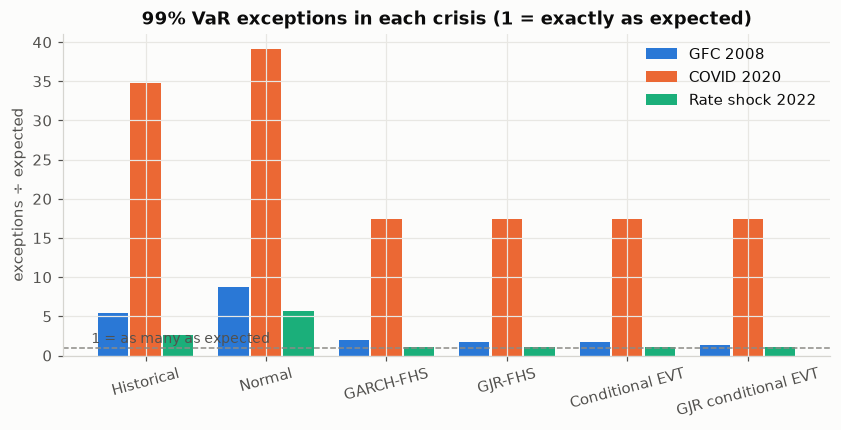

crisis,COVID 2020,GFC 2008,Rate shock 2022
model,,,
Historical,1.87,0.70,0.48
Normal,1.77,0.71,0.39
GARCH-FHS,1.13,0.39,0.29
GJR-FHS,1.05,0.35,0.13
Conditional EVT,1.04,0.37,0.32
GJR conditional EVT,1.02,0.35,0.23


In [7]:
CRISES = {"GFC 2008": ("2007-10-10", "2009-03-09"), "COVID 2020": ("2020-02-20", "2020-03-23"), "Rate shock 2022": ("2022-01-04", "2022-10-12")}
rows = []
for m in MODELS:
    for name, (a, b) in CRISES.items():
        d = fc[m].loc[a:b]
        h = d["hit_0.99"]; x, T = int(h.sum()), len(h)
        rows.append({"model": m, "crisis": name, "days": T, "exceptions": x, "expected": 0.01 * T,
                     "P(≥ this many | model right)": float(st.binom.sf(x - 1, T, 0.01)),
                     "average breach % of NAV": float((d["loss"] - d["var_0.99"])[h == 1].mean() * 100) if x else 0.0})
crisis = pd.DataFrame(rows)
display(crisis.pivot(index="model", columns="crisis", values="exceptions").reindex(MODELS))
fig, ax = plt.subplots(figsize=(9, 3.8))
xp = np.arange(len(MODELS))
for j, (name, colr) in enumerate(zip(CRISES, [BLUE, ORANGE, AQUA])):
    sub = crisis[crisis.crisis == name].set_index("model").reindex(MODELS)
    ax.bar(xp + (j - 1) * 0.27, sub["exceptions"] / sub["expected"], width=0.25, color=colr, label=name)
ax.axhline(1, color=GREY, linestyle="--", linewidth=1)
ax.text(-0.45, 1.6, "1 = as many as expected", color=INK2, fontsize=9, ha="left")
ax.set_xticks(xp, MODELS, rotation=15)
ax.set(ylabel="exceptions ÷ expected", title="99% VaR exceptions in each crisis (1 = exactly as expected)")
ax.legend(loc="upper right")
plt.show()
crisis.pivot(index="model", columns="crisis", values="average breach % of NAV").reindex(MODELS).round(2)

**Finding:** the volatility-adjusted models get the **GFC** (4 exceptions vs 3.6 expected) and **2022** (2 vs 1.95) about right, and their breaches are small (about 1% of NAV in the GFC, 0.2–0.3% in 2022; GJR models smallest). **Every model fails in the COVID crash**: 4–6 exceptions in 23 days against 0.23 expected, because volatility jumped faster than any daily model can update. Historical and normal VaR also fail the GFC (5–9 times too many exceptions).
**Decision:** this is the honest answer to the booklet's question on "how different modelling approaches perform under stressed market conditions". No daily risk model foresees a COVID-speed crash, which is **why** the endowment also has a crisis budget (D2) and stress scenarios (notebook 05), not just a VaR limit.

## 6 · Exception log for the champion (validation period; Basel 1996 recommends explaining every breach)

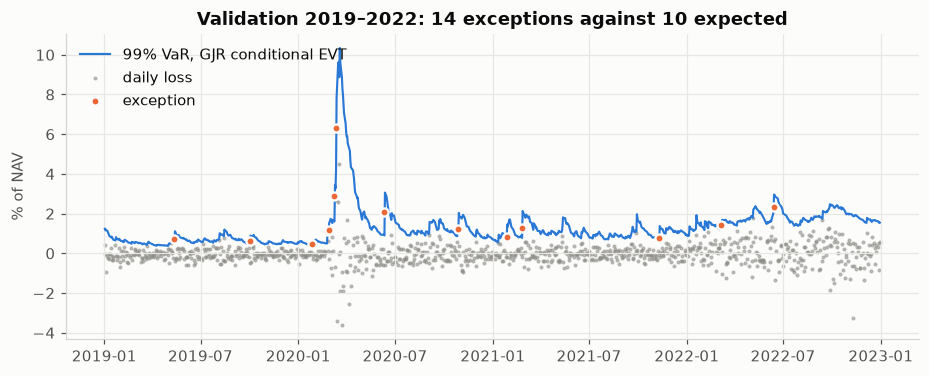

,loss,var_0.99,excess,cause
date,,,,
2019-05-13 00:00:00,0.74%,0.67%,0.07%,US–China trade war: China retaliates with tariffs on $60bn of US goods (S&P 500 −2.4%)
2019-10-02 00:00:00,0.64%,0.58%,0.06%,Growth scare: ISM manufacturing at its lowest since 2009 (S&P 500 −1.8%)
2020-01-27 00:00:00,0.49%,0.42%,0.07%,"First COVID scare: Wuhan outbreak spreads, travel stocks fall (S&P 500 −1.6%)"
2020-02-24 00:00:00,1.13%,0.50%,0.63%,COVID spreads in Italy
2020-02-27 00:00:00,1.19%,1.15%,0.04%,COVID sell-off
2020-03-09 00:00:00,2.90%,1.60%,1.30%,COVID + oil price war
2020-03-12 00:00:00,6.33%,4.23%,2.10%,COVID: US travel ban
2020-06-11 00:00:00,2.08%,0.90%,1.19%,"Second-wave fears (Texas, Florida, Arizona) and a gloomy Fed outlook (S&P 500 −5.9%)"
2020-10-28 00:00:00,1.25%,1.05%,0.20%,COVID cases surge in the US and Europe; new lockdowns in France and Germany (S&P 500 −3.5%)


In [8]:
EVENTS = {"2019-05-13": "US–China trade war: China retaliates with tariffs on $60bn of US goods (S&P 500 −2.4%)",
          "2019-10-02": "Growth scare: ISM manufacturing at its lowest since 2009 (S&P 500 −1.8%)",
          "2020-01-27": "First COVID scare: Wuhan outbreak spreads, travel stocks fall (S&P 500 −1.6%)",
          "2020-02-24": "COVID spreads in Italy", "2020-02-27": "COVID sell-off", "2020-03-09": "COVID + oil price war",
          "2020-03-12": "COVID: US travel ban", "2020-03-16": "COVID: worst day of the crash", "2020-03-18": "COVID: dash for cash",
          "2020-06-11": "Second-wave fears (Texas, Florida, Arizona) and a gloomy Fed outlook (S&P 500 −5.9%)",
          "2020-10-28": "COVID cases surge in the US and Europe; new lockdowns in France and Germany (S&P 500 −3.5%)",
          "2021-01-27": "Fed statement, hedge funds de-risk during the GameStop squeeze (S&P 500 −2.6%)",
          "2021-02-25": "Bond tantrum: record-weak 7-year auction, 10-year yield above 1.6% (Nasdaq-100 −3.5%)",
          "2021-11-10": "US CPI 6.2%, highest since 1990: stocks and bonds fall together (S&P 500 −0.8%)",
          "2022-03-07": "Russia–Ukraine: oil near $130 on talk of a Russian oil ban (S&P 500 −3.0%)",
          "2022-06-13": "US CPI surprise; Fed 75 bp expected", "2022-09-13": "US CPI surprise", "2022-04-29": "rate-shock sell-off",
          "2022-05-05": "rate-shock sell-off after the Fed meeting"}
# Causes checked against contemporaneous news reports (CNN, Reuters, CNBC, NPR, AP, Bloomberg; listed in doc/decisions/exception_log.md)
chosen = champion or base
d = fc[chosen].loc[VAL[0]:VAL[1]]
log = d[d["hit_0.99"] == 1][["loss", "var_0.99"]].assign(excess=lambda t: t["loss"] - t["var_0.99"])
log["cause"] = [EVENTS.get(str(i.date()), "owner to explain") for i in log.index]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(d.index, d["var_0.99"] * 100, color=BLUE, linewidth=1.4, label=f"99% VaR, {chosen}")
ax.scatter(d.index, d["loss"] * 100, s=3, color=GREY, alpha=0.5, label="daily loss")
ax.scatter(log.index, log["loss"] * 100, s=28, color=ORANGE, zorder=3, edgecolor=SURFACE, linewidth=1.5, label="exception")
ax.set(ylabel="% of NAV", title=f"Validation 2019–2022: {len(log)} exceptions against {0.01 * len(d):.0f} expected")
ax.legend(loc="upper left")
plt.show()
log.style.format({"loss": "{:.2%}", "var_0.99": "{:.2%}", "excess": "{:.2%}"})

In [9]:
# Breach anatomy from our own data: who lost, what moved, and how the losses compare with the ES forecast
def fred_day(name):
    s = pd.read_parquet(RAW / f"fred_{name}.parquet").iloc[:, -1]; s.index = pd.to_datetime(s.index)
    return s.loc[:END].dropna()
moves = pd.DataFrame({"Δ10y (bp)": fred_day("DGS10").diff() * 100, "ΔVIX": fred_day("VIXCLS").diff(),
                      "oil %": fred_day("DCOILWTICO").where(lambda s: s > 0).pct_change() * 100})
flags = pd.read_parquet(ART / "quality_flags.parquet")
flag_days = set(pd.to_datetime(flags["date"]))
rows = []
for day, r in log.iterrows():
    w = held.loc[day].to_numpy(); ret = R.loc[day]
    contrib = pd.Series(w * ret.to_numpy(), index=TICKERS)
    eq, bond = contrib[EQUITY].sum(), contrib["AGG"]
    rows.append({"date": day.date(), "loss": r.loss, "excess / VaR": r.excess / r["var_0.99"],
                 "equity contrib.": eq, "AGG contrib.": bond, "GLD contrib.": contrib["GLD"],
                 "worst ETF": f"{ret.idxmin()} {ret.min():.1%}", **moves.reindex([day]).iloc[0].to_dict(),
                 "stocks and bonds fell together": eq < 0 and bond < 0, "data flag": day in flag_days,
                 "loss ÷ ES forecast": r.loss / d.loc[day, "es_0.99"],
                 # Basel (1996) categories, decided by the model's own tail forecast: a loss no larger than the forecast ES is
                 # the size of 1-in-100 loss the model expected ("bad luck"); a larger one means the market moved more than
                 # forecast. A data flag counts as an integrity problem only if no market event explains the day.
                 "Basel category": ("data integrity" if day in flag_days and log.loc[day, "cause"] == "owner to explain" else
                                    "bad luck (within the forecast ES)" if r.loss <= d.loc[day, "es_0.99"] else "market moved more than forecast")})
anatomy = pd.DataFrame(rows).set_index("date")
display(anatomy.style.format({"loss": "{:.2%}", "excess / VaR": "{:.0%}", "equity contrib.": "{:+.2%}", "AGG contrib.": "{:+.2%}",
                              "GLD contrib.": "{:+.2%}", "loss ÷ ES forecast": "{:.2f}", "Δ10y (bp)": "{:+.0f}", "ΔVIX": "{:+.1f}", "oil %": "{:+.1f}"}))

# Statistical checks
# 1. Do breaches come from calm periods (a low VaR that jumps too slowly)? Exact test: breach rate by VaR tercile.
terc = pd.qcut(d["var_0.99"], 3, labels=["low VaR", "middle", "high VaR"])
tab = pd.crosstab(terc, d["hit_0.99"]).reindex(columns=[0, 1], fill_value=0)
low_vs_rest = [[tab.loc["low VaR", 1], tab.loc["low VaR", 0]], [tab.loc[["middle", "high VaR"], 1].sum(), tab.loc[["middle", "high VaR"], 0].sum()]]
odds, p_fisher = st.fisher_exact(low_vs_rest)
# 2. Are breach-day losses as large as the ES forecast said? Under a correct ES, mean(loss / ES) on breach days is about 1.
ratio = (d.loc[log.index, "loss"] / d.loc[log.index, "es_0.99"]).to_numpy()
rng_b = np.random.default_rng(20261029)
boot = np.array([rng_b.choice(ratio, len(ratio)).mean() for _ in range(5000)])
# 3. Do the breaches bunch in calendar time? Gaps between breaches against a geometric distribution with p = 1%.
gaps = np.diff([d.index.get_loc(t) for t in log.index])
p_gap = st.kstest(gaps, st.geom(0.01).cdf).pvalue
print("breach rate by VaR tercile:", {k: f"{v[1]}/{v.sum()}" for k, v in tab.iterrows()}, f"| Fisher exact, low vs rest: p = {p_fisher:.2f}")
print(f"breach-day loss ÷ ES forecast: mean {ratio.mean():.2f} (bootstrap 90% interval {np.quantile(boot, .05):.2f}–{np.quantile(boot, .95):.2f}); 1 = ES right on average")
print(f"days between breaches: median {np.median(gaps):.0f} (geometric with p = 1% has median 69); KS p = {p_gap:.3f}")
print("Basel categories:", anatomy["Basel category"].value_counts().to_dict(),
      f"| stocks and bonds fell together on {int(anatomy['stocks and bonds fell together'].sum())} of {len(anatomy)} breach days",
      f"| breaches with a documented market cause: {int((log['cause'] != 'owner to explain').sum())} of {len(log)}")

,loss,excess / VaR,equity contrib.,AGG contrib.,GLD contrib.,worst ETF,Δ10y (bp),ΔVIX,oil %,stocks and bonds fell together,data flag,loss ÷ ES forecast,Basel category
date,,,,,,,,,,,,,
2019-05-13,0.74%,11%,-0.86%,+0.11%,+0.02%,XLK -3.8%,-7,+4.5,-1.1,False,False,0.95,bad luck (within the forecast ES)
2019-10-02,0.64%,11%,-0.69%,+0.05%,+0.00%,XLE -2.5%,-5,+2.0,-1.7,False,False,0.99,bad luck (within the forecast ES)
2020-01-27,0.49%,16%,-0.69%,+0.20%,+0.00%,EEM -3.5%,-9,+3.7,-1.8,False,False,1.07,market moved more than forecast
2020-02-24,1.13%,127%,-1.34%,+0.21%,+0.00%,XLE -4.6%,-8,+8.0,-3.7,False,False,2.11,market moved more than forecast
2020-02-27,1.19%,3%,-1.20%,+0.01%,+0.00%,XLK -5.4%,-3,+11.6,-3.1,False,False,0.96,bad luck (within the forecast ES)
2020-03-09,2.90%,81%,-2.82%,-0.08%,+0.00%,XLE -20.1%,-20,+12.5,-24.5,True,True,1.43,market moved more than forecast
2020-03-12,6.33%,50%,-3.73%,-2.60%,-0.00%,XLE -12.5%,+6,+21.6,-4.7,True,True,1.19,market moved more than forecast
2020-06-11,2.08%,132%,-1.92%,-0.10%,-0.07%,XLE -9.4%,-9,+13.2,-7.9,True,False,1.77,market moved more than forecast
2020-10-28,1.25%,19%,-1.09%,-0.09%,-0.08%,XLK -4.2%,+0,+6.9,-5.3,True,False,0.82,bad luck (within the forecast ES)


breach rate by VaR tercile: {'low VaR': '7/336', 'middle': '4/336', 'high VaR': '3/336'} | Fisher exact, low vs rest: p = 0.25
breach-day loss ÷ ES forecast: mean 1.11 (bootstrap 90% interval 0.95–1.29); 1 = ES right on average
days between breaches: median 63 (geometric with p = 1% has median 69); KS p = 0.176
Basel categories: {'bad luck (within the forecast ES)': 8, 'market moved more than forecast': 6} | stocks and bonds fell together on 8 of 14 breach days | breaches with a documented market cause: 14 of 14


**Finding (every breach explained, checked two ways: our own data and contemporaneous news):**
- **All 14 breaches have a documented market cause**, and none is a data error. The two days our outlier screen flagged (9 and 12 March 2020) are genuine crash days (XLE −20% and −12.5%), so they stay in, as the data rules require.
- **8 of 14 were "bad luck" in the Basel sense:** the loss was no larger than the model's own 99% ES forecast, i.e. the size of 1-in-100 day the model expected. **6 were larger than forecast:** the COVID onset (27 Jan, 24 Feb, 9 and 12 Mar 2020), the second-wave scare (11 Jun 2020) and the bond tantrum (25 Feb 2021). All six are **sudden switches from calm to stress**, where a volatility model needs a few days to catch up.
- **Is the ES forecast biased?** On breach days the loss averaged 1.11 × the ES forecast (bootstrap 90% interval 0.95–1.29). The interval contains 1, so there is no evidence that the ES is too low on average (consistent with the Acerbi-Szekely test being green).
- **Do breaches come from calm periods?** 7 of the 14 fell in the lowest-VaR third of days (4.7 expected), the direction the GARCH lag predicts, but it is not significant (Fisher exact p = 0.25; 14 breaches give little power).
- **Do they bunch?** The median gap between breaches is 63 trading days against 69 expected if they were independent (KS p = 0.18), consistent with Christoffersen's p = 0.53.
- **The 2021–2022 pattern:** on 8 of 14 breach days stocks **and** bonds fell together, including every breach from February 2021 on (bond tantrum, the 6.2% CPI print, the oil spike, the June 2022 CPI surprise). This is the rate-hiking regime of hypothesis H1 showing up in the risk model's misses.

**Decision:** no model change (the locked rule changes the model only if it fails a test). The log, with sources, is in `doc/decisions/exception_log.md` and goes in the report appendix (gap G20). For the memo: the model's misses come at regime switches, which is why the fund also holds a crisis budget, stress tests and the D9 alert. Drafted with AI assistance; causes verified against news reports; **accepted by the owner (team lead) on 2026-10-29**.

## 7 · How much can these tests tell us?

The power of Kupiec's test to catch a model whose true exception rate is **double** the claimed 1%, at the canonical 250 days and over our 4-year validation period.

In [10]:
def kupiec_power(T, p0=0.01, p1=0.02, level=0.05):
    xs = np.arange(T + 1); crit = st.chi2.ppf(1 - level, 1)
    def lr(x):
        ph = x / T
        ll = lambda q: (T - x) * np.log(1 - q) + (x * np.log(q) if x else 0.0)
        return -2 * (ll(p0) - (ll(ph) if 0 < x < T else 0.0))
    rej = np.array([lr(x) > crit for x in xs])
    return float(st.binom.pmf(xs[rej], T, p1).sum()), float(st.binom.pmf(xs[rej], T, p0).sum())
pd.DataFrame({T: dict(zip(["power to detect a doubled rate", "actual false-alarm rate"], kupiec_power(T))) for T in (250, 1008)}).T.style.format("{:.0%}")

,power to detect a doubled rate,actual false-alarm rate
250,24%,9%
1008,79%,6%


**Finding:** over 250 days, Kupiec's test catches a model that is wrong by a factor of two only **24%** of the time, and its false-alarm rate is 9%, not the nominal 5%. Over our 4-year validation period the power rises to **79%**. A model that "passes" a single year proves very little; that is why the champion is chosen on four years.

## 8 · Reconciliation with the pipeline (option C)

Option C (inputs_lock) lets the pipeline run the official final test only if it reproduces this notebook first. The pipeline now backtests the same pre-registered 35%-equity frontier portfolio with its own code (`risk/garch.py`, `risk/evt.py`, `backtest/engine.py`). Its forecasts must give the **same exceptions and pinball loss** as the independent code above, model by model.

In [11]:
sel = pd.read_parquet(ART / "backtest_selection_val_500.parquet")
champ = json.loads((ART / "champion.json").read_text())
rows = []
for m in ["Historical", "GARCH-FHS", "GJR-FHS", "Conditional EVT", "GJR conditional EVT"]:
    f = m.lower().replace(" ", "_").replace("-", "_")
    b = pd.read_parquet(ART / f"backtest_{f}_500.parquet").loc[VAL[0]:VAL[1]]
    ours = fc[m].loc[VAL[0]:VAL[1]]
    rows.append({"model": m, "exceptions ours": int(ours["hit_0.99"].sum()), "exceptions pipeline": int(sel.loc[m, "exceptions"]),
                 "pinball ours (×10⁴)": pinball(ours) * 1e4, "pinball pipeline (×10⁴)": float(sel.loc[m, "pinball"]) * 1e4,
                 "largest VaR gap (bp of NAV)": float((ours["var_0.99"] - b["var_0.99"]).abs().max() * 1e4)})
recon = pd.DataFrame(rows).set_index("model")
assert (recon["exceptions ours"] == recon["exceptions pipeline"]).all(), "pipeline and notebook disagree on exceptions"
assert np.allclose(recon["pinball ours (×10⁴)"], recon["pinball pipeline (×10⁴)"], rtol=1e-3), "pipeline and notebook disagree on pinball"
print(f"pipeline focus: {json.loads((ART / 'status.json').read_text())['focus_portfolio']}; "
      f"champion: {champ['champion']} (the rule picks {champ['rule_choice']})")
recon.style.format({"pinball ours (×10⁴)": "{:.4f}", "pinball pipeline (×10⁴)": "{:.4f}", "largest VaR gap (bp of NAV)": "{:.2f}"})

pipeline focus: Frontier 35% equity; champion: GJR conditional EVT (the rule picks GJR conditional EVT)


,exceptions ours,exceptions pipeline,pinball ours (×10⁴),pinball pipeline (×10⁴),largest VaR gap (bp of NAV)
model,,,,,
Historical,13,13,3.5557,3.5557,0.00
GARCH-FHS,12,12,2.1319,2.1319,0.00
GJR-FHS,13,13,2.0202,2.0202,0.01
Conditional EVT,14,14,2.0398,2.0398,0.02
GJR conditional EVT,14,14,1.9945,1.9945,0.03


**Finding:** the pipeline reproduces this notebook's exceptions and pinball loss for every model (the two codes were written separately), and its own rule picks the same champion. Option C holds: the pipeline's `final_test` runs the official test once after the freeze, and §2 of this notebook replicates it as the effective challenge.

## Evidence table and the decision to lock

| Claim | Evidence | Status |
|---|---|---|
| Volatility-adjusted models are needed | §2: historical clusters, normal fails; GARCH-based models pass | **Strong** |
| GJR conditional EVT is the best model | §3: lowest pinball and FZ0, but not significantly better than plain conditional EVT | **Chosen by the locked rule; statistically tied** |
| H3: the volatility filter is well specified | §4: GJR better, but clustering remains in 44% of short windows | **Partly supported**, disclosed as a limitation |
| Models perform acceptably in crises (Layer 4) | §5: right in the GFC and 2022, all fail in COVID's speed | **Strong** (and honest about COVID) |
| H4 (final test) | — | Run once after the freeze on 2023–2026 |

**Locked for the freeze:** champion = **GJR conditional EVT** (GJR-GARCH(1,1) with Student-t errors on a 500-day window, refitted every 5 days; GPD tail on the top 10% of standardised losses). Recorded in `doc/decisions/inputs_lock.md` and `config.yaml → backtest.champion`; the pipeline's `final_test` runs it.

## 9 · The one-shot final test, checked independently (runs only after the freeze tag)

The production code ran the final test once on 2023-01-01 → the snapshot end (`quantedge.backtest.final_test`, recorded in `doc/decisions/methodology_freeze.md`). This section reruns **this notebook's own forecasting code** on the same days, with nothing re-tuned (same models, window, refit cadence, champion), and checks that both codes give the same answer, as §8 did for validation.

**Pre-registered (spec §5 step 7):** the champion must pass Kupiec, Christoffersen and the Basel zone on the test; if it fails, the limits use the passing model with the higher current ES; if none passes, REJECT. **H4** (stated before testing): the champion's 99% VaR has correct coverage and independent exceptions on 2023–26.

In [12]:
import subprocess
tag = subprocess.run(["git", "-C", str(ROOT), "tag", "-l", "methodology-freeze-v1"], capture_output=True, text=True).stdout.strip()
assert tag, "the final test period stays locked until the freeze tag exists"
rawT = pd.read_parquet(RAW / "prices.parquet"); rawT["date"] = pd.to_datetime(rawT["date"])
R = rawT.pivot(index="date", columns="ticker", values="adj_close").sort_index()[TICKERS].pct_change(fill_method=None).iloc[1:]
qe = R.index.to_series().groupby(R.index.to_period("Q")).max()
TAUS = [d for d in qe if pd.Timestamp("2007-12-31") <= d < R.index[-1]]
WPATH = {tau: min_var_at(X_EQ, LedoitWolf().fit(R.loc[:tau].iloc[-W_OPT:].to_numpy()).covariance_ * 252) for tau in TAUS}
fres = json.loads((ART / "final_test_result.json").read_text())
TEST = (pd.Timestamp(fres["test_start"]), pd.Timestamp(fres["test_end"]))     # the frozen snapshot end, as production
DAYS = R.index[(R.index >= TEST[0]) & (R.index <= TEST[1])]
held = pd.DataFrame(WPATH).T.reindex(R.index, method="ffill").shift(1).loc[DAYS]
t0 = time.time()
ft = {m: run_model(m) for m in MODELS}
print(f"final test {TEST[0].date()} to {TEST[1].date()}: {len(DAYS)} days, {len(MODELS)} models, {time.time() - t0:.0f}s")
rows = []
for m in MODELS:
    d = ft[m]; h = d["hit_0.99"].to_numpy()
    x, ex, kp = kupiec(h); ip = christoffersen(h); zone, gmax, rmin = basel_zone(x, len(h))
    lr_cc = st.chi2.isf(kp, 1) + (st.chi2.isf(ip, 1) if not np.isnan(ip) else 0.0)   # LR_cc = LR_uc + LR_ind
    cc = float(st.chi2.sf(lr_cc, 2))
    roll = pd.Series(h, index=d.index).rolling(250).sum().dropna()
    rows.append({"model": m, "days": len(h), "exceptions": x, "expected": ex, "Kupiec p": kp, "independence p": ip,
                 "conditional coverage p": cc, "adapted zone": zone, "rolling windows in red": float((roll >= 10).mean()),
                 # pass rule as in the frozen production code: Kupiec and conditional coverage at 5%, no red zone or window
                 "passes": kp >= 0.05 and cc >= 0.05 and zone != "red" and (roll >= 10).mean() == 0,
                 "passes with independence p instead": kp >= 0.05 and (np.isnan(ip) or ip >= 0.05) and zone != "red",
                 "pinball (×10⁴)": pinball(d) * 1e4, "current 99% ES": float(d["es_0.99"].iloc[-1])})
test_tab = pd.DataFrame(rows).set_index("model")
champ_t = json.loads((ART / "champion.json").read_text())["champion"]
if test_tab.loc[champ_t, "passes"]:
    limits_by = champ_t
else:
    ok = test_tab[test_tab["passes"]]
    limits_by = ok["current 99% ES"].idxmax() if len(ok) else None
print(f"champion {champ_t}: {'passes' if test_tab.loc[champ_t, 'passes'] else 'FAILS'}; limits use: {limits_by or 'none: REJECT'}")
test_tab.style.format({"expected": "{:.1f}", "Kupiec p": "{:.3f}", "independence p": "{:.3f}", "conditional coverage p": "{:.3f}", "rolling windows in red": "{:.0%}",
                       "pinball (×10⁴)": "{:.3f}", "current 99% ES": "{:.2%}"})

final test 2023-01-01 to 2026-10-26: 957 days, 6 models, 15s
champion GJR conditional EVT: passes; limits use: GJR conditional EVT


,days,exceptions,expected,Kupiec p,independence p,conditional coverage p,adapted zone,rolling windows in red,passes,passes with independence p instead,pinball (×10⁴),current 99% ES
model,,,,,,,,,,,,
Historical,957,6,9.6,0.213,0.000,0.001,green,0%,False,False,1.556,1.69%
Normal,957,7,9.6,0.381,0.001,0.002,green,0%,False,False,1.545,1.01%
GARCH-FHS,957,8,9.6,0.600,0.001,0.004,green,0%,False,False,1.464,1.14%
GJR-FHS,957,7,9.6,0.381,0.038,0.079,green,0%,True,False,1.435,1.04%
Conditional EVT,957,9,9.6,0.852,0.002,0.008,green,0%,False,False,1.428,1.12%
GJR conditional EVT,957,9,9.6,0.852,0.069,0.189,green,0%,True,True,1.405,1.01%


In [13]:
# Two codes, one answer: this notebook against the production final test
recon = []
for m in MODELS:
    f = ART / f"final_test_{m.lower().replace(' ', '_').replace('-', '_')}.parquet"
    if not f.exists():
        continue
    pdf = pd.read_parquet(f).loc[DAYS[0]:DAYS[-1]]
    nb_ = ft[m].loc[pdf.index]
    recon.append({"model": m, "days": len(pdf), "exceptions (notebook)": int(nb_["hit_0.99"].sum()),
                  "exceptions (production)": int(pdf["hit_0.99"].sum()),
                  "largest VaR gap (bp of NAV)": float((nb_["var_0.99"] - pdf["var_0.99"]).abs().max() * 1e4),
                  "pinball ×10⁴ (notebook)": pinball(nb_) * 1e4, "pinball ×10⁴ (production)": pinball(pdf) * 1e4})
recon = pd.DataFrame(recon).set_index("model")
print(f"production record: run {fres['run_utc']}, {fres['days']} common days; limits model {fres.get('limits_model')}; rule: {fres.get('rule')}")
display(recon.style.format({"largest VaR gap (bp of NAV)": "{:.2f}", "pinball ×10⁴ (notebook)": "{:.3f}", "pinball ×10⁴ (production)": "{:.3f}"}))
assert (recon["exceptions (notebook)"] == recon["exceptions (production)"]).all(), "the two codes disagree on exceptions"
assert np.allclose(recon["pinball ×10⁴ (notebook)"], recon["pinball ×10⁴ (production)"], rtol=1e-3)
assert fres.get("limits_model") == limits_by

production record: run 2026-10-29T01:48:41Z, 955 common days; limits model GJR conditional EVT; rule: the champion passes its backtests


,days,exceptions (notebook),exceptions (production),largest VaR gap (bp of NAV),pinball ×10⁴ (notebook),pinball ×10⁴ (production)
model,,,,,,
Historical,957,6,6,0.00,1.556,1.556
Normal,957,7,7,0.00,1.545,1.545
GARCH-FHS,957,8,8,0.20,1.464,1.464
GJR-FHS,957,7,7,0.35,1.435,1.435
Conditional EVT,957,9,9,0.20,1.428,1.428
GJR conditional EVT,957,9,9,0.35,1.405,1.405


**Finding (final test, 2023-01-01 → 2026-10-26, run once after the freeze):**
- **H4 supported.** The champion, GJR conditional EVT, had **9 breaches against 9.6 expected** over 957 days (Kupiec p = 0.85, independence p = 0.07, conditional coverage p = 0.19, every rolling 250-day window green). It also had the **lowest 99% pinball loss** of all eleven models in production and of the six here. The model chosen on 2019–2022 was the best one on data it had never seen.
- **Asymmetry mattered out of sample.** Every model without GJR's "bad news raises volatility more" term failed, because its breaches bunched together (conditional coverage p ≤ 0.008), including plain conditional EVT, which ties the champion on validation. Notebook 03's residual test (H3) had flagged exactly this: plain GARCH left clustering, GJR did not.
- **Two codes, one answer:** on the 957 test days this notebook and the production code agree on every breach count and every pinball loss; the largest daily VaR difference is 0.35 bp of NAV.
- **Pre-committed rules applied as written:** the champion passes (production rule: Kupiec and conditional coverage at 5%), so the limits use it; Linear QR passes coverage but is 5.4% worse than the champion, more than the 2% margin, so it is not adopted. GJR-FHS passes on conditional coverage but not on the stricter independence test alone; the champion passes both.
- **Honest limits:** 957 days give about 9.6 expected breaches, so Kupiec's power against a doubled breach rate is moderate (§7); the result says the model is not wrong in a detectable way, not that it is right.